In [1]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm
import pandas as pd
import numpy as np
import scipy.stats as st
from functools import partial

from finsler_learning.shepplogan_pipeline.aggregate_extrapolation_ablation import (
    main as get_datas,
)

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_path = Path(
    "/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11_extrapolation_ablation"
)
df_mono_extra = get_datas(base_path)
df_mono_extra = df_mono_extra.sort_values(
    by=["Base Metric", "Zeta", "Alpha", "Finsler", "Eta"]
)
df_mono_extra = df_mono_extra[~df_mono_extra.isna().any(axis=1)]
df_mono_extra

,Base Metric,Finsler,Eta,Zeta,Alpha,Kendall Tau Median,Kendall Tau 25%,Kendall Tau 75%,Relative Variation Median,Relative Variation 25%,Relative Variation 75%,FWD
726,CovCentroids,False,0.999,0.0,0.1,0.000000,-0.240328,0.348776,0.000000,0.000000,0.042616,0.231756
175,CovCentroids,True,0.900,0.0,0.1,0.973824,0.966092,0.981495,1.941027,1.550637,2.411256,0.252270
407,CovCentroids,True,0.990,0.0,0.1,0.976388,0.969536,0.983616,2.112660,1.696947,2.592170,0.238214
727,CovCentroids,True,0.999,0.0,0.1,0.978093,0.970824,0.983192,2.117652,1.708022,2.612079,0.254548
718,CovCentroids,False,0.999,0.0,0.5,-0.035818,-0.443857,0.435672,0.000000,-0.223596,0.197460,0.240528
...,...,...,...,...,...,...,...,...,...,...,...,...
117,LAND RBF,True,0.900,1.0,3.0,1.000000,1.000000,1.000000,52.403553,42.185682,64.501385,0.289704
349,LAND RBF,True,0.990,1.0,3.0,1.000000,1.000000,1.000000,54.803993,42.973063,69.018147,0.285973
661,LAND RBF,True,0.999,1.0,3.0,1.000000,1.000000,1.000000,54.872734,43.231975,68.900240,0.295245
668,LAND RBF,False,0.999,1.0,5.0,-0.003367,-0.870828,0.883346,0.227453,-3.721912,3.762325,0.238577


### Paper analysis: effect of $\eta$

For CovCentroids Randers at $\zeta=0.9$ and $\alpha=5$, compare the available $\eta=0.999$ and $\eta=0.5$ runs. The table reports median and interquartile range for Kendall Tau and relative variation.

In [3]:
eta_paper_comparison = df_mono_extra.loc[
    (df_mono_extra["Base Metric"] == "CovCentroids")
    & df_mono_extra["Finsler"]
    & (df_mono_extra["Zeta"] == 0.9)
    & (df_mono_extra["Alpha"] == 5)
    & df_mono_extra["Eta"].isin([0.999, 0.5]),
    [
        "Eta",
        "Kendall Tau Median",
        "Kendall Tau 25%",
        "Kendall Tau 75%",
        "Relative Variation Median",
        "Relative Variation 25%",
        "Relative Variation 75%",
    ],
].sort_values("Eta", ascending=False)
eta_paper_comparison = eta_paper_comparison.round(
    {
        "Kendall Tau Median": 2,
        "Kendall Tau 25%": 2,
        "Kendall Tau 75%": 2,
        "Relative Variation Median": 2,
        "Relative Variation 25%": 2,
        "Relative Variation 75%": 2,
    }
)
eta_paper_comparison

,Eta,Kendall Tau Median,Kendall Tau 25%,Kendall Tau 75%,Relative Variation Median,Relative Variation 25%,Relative Variation 75%
551,0.999,1.0,1.0,1.0,83.82,64.27,105.01
431,0.500,1.0,1.0,1.0,53.27,44.69,63.28


### Paper analysis: effect of $\alpha$

For CovCentroids Randers at $\eta=0.999$ and $\zeta=0.9$, compare the available $\alpha=5$ and $\alpha=1$ runs using the same median and interquartile-range summaries.

In [4]:
alpha_paper_comparison = df_mono_extra.loc[
    (df_mono_extra["Base Metric"] == "CovCentroids")
    & df_mono_extra["Finsler"]
    & (df_mono_extra["Zeta"] == 0.9)
    & (df_mono_extra["Eta"] == 0.999)
    & df_mono_extra["Alpha"].isin([5, 1]),
    [
        "Alpha",
        "Kendall Tau Median",
        "Kendall Tau 25%",
        "Kendall Tau 75%",
        "Relative Variation Median",
        "Relative Variation 25%",
        "Relative Variation 75%",
    ],
].sort_values("Alpha", ascending=False)
alpha_paper_comparison = alpha_paper_comparison.round(
    {
        "Kendall Tau Median": 2,
        "Kendall Tau 25%": 2,
        "Kendall Tau 75%": 2,
        "Relative Variation Median": 2,
        "Relative Variation 25%": 2,
        "Relative Variation 75%": 2,
    }
)
alpha_paper_comparison

,Alpha,Kendall Tau Median,Kendall Tau 25%,Kendall Tau 75%,Relative Variation Median,Relative Variation 25%,Relative Variation 75%
551,5.0,1.0,1.0,1.0,83.82,64.27,105.01
575,1.0,1.0,1.0,1.0,21.70,18.02,25.53


In [5]:
def _plot_quantile_points(data, x, y, lower, upper, show_interval, color, label, **kwargs):
    data = data.sort_values(x)
    x_values = data[x].to_numpy(dtype=float)
    y_values = data[y].to_numpy(dtype=float)
    yerr = None
    if show_interval:
        yerr = np.vstack(
            (
                y_values - data[lower].to_numpy(dtype=float),
                data[upper].to_numpy(dtype=float) - y_values,
            )
        )
    plt.errorbar(
        x_values,
        y_values,
        yerr=yerr,
        fmt="o-",
        color=color,
        label=label,
        capsize=3,
    )


def _plot_ablation_summary(
    df, x, row, col, finsler, y, x_label, row_title, col_title, suptitle
):
    if y == "Kendall Tau Median":
        lower = "Kendall Tau 25%"
        upper = "Kendall Tau 75%"
        y_label = "Kendall Tau"
        show_interval = True
    elif y == "Relative Variation Median":
        lower = "Relative Variation 25%"
        upper = "Relative Variation 75%"
        y_label = "Relative Variation (%)"
        show_interval = True
    elif y == "FWD":
        lower = None
        upper = None
        y_label = "FWD"
        show_interval = False
    else:
        raise ValueError(
            "y must be 'Kendall Tau Median', 'Relative Variation Median', or 'FWD'"
        )

    plot_data = df.loc[df["Finsler"] == finsler].copy()
    required_columns = [y]
    if show_interval:
        required_columns.extend([lower, upper])
    plot_data = plot_data.dropna(subset=required_columns)
    if plot_data.empty:
        raise ValueError(f"No values to plot for Finsler={finsler}, y={y}")

    x_values = sorted(plot_data[x].unique())
    x_positions = {value: index for index, value in enumerate(x_values)}
    plot_data["_plot_x"] = plot_data[x].map(x_positions)

    g = sns.FacetGrid(
        data=plot_data,
        col=col,
        row=row,
        hue="Base Metric",
        height=4,
        aspect=1.5,
        legend_out=True,
    )
    g.map_dataframe(
        _plot_quantile_points,
        x="_plot_x",
        y=y,
        lower=lower,
        upper=upper,
        show_interval=show_interval,
    )
    g.add_legend(title="Base Metric")
    g.set_titles(col_template=col_title, row_template=row_title)
    g.set_axis_labels(x_label, y_label)

    x_tick_labels = [f"{value:g}" for value in x_values]
    for ax in g.axes.flatten():
        ax.set_xticks(range(len(x_values)), x_tick_labels)
        ax.grid(True, which="both", linestyle="--", linewidth=0.5)
        ax.title.set_fontsize(18)
        ax.xaxis.label.set_fontsize(18)
        ax.yaxis.label.set_fontsize(18)
        ax.tick_params(axis="both", which="major", labelsize=16)

    if g.legend is not None:
        g.legend.get_title().set_fontsize(20)
        for text in g.legend.get_texts():
            text.set_fontsize(16)

    if suptitle is not None:
        g.figure.suptitle(suptitle, fontsize=18)
    g.figure.tight_layout(rect=[0, 0, 0.9, 0.95])
    plt.show()
    return g.figure


def plot_extrapolation_performance(df, y="Kendall Tau Median", finsler=True, suptitle=None):
    return _plot_ablation_summary(
        df,
        x="Eta",
        row="Zeta",
        col="Alpha",
        finsler=finsler,
        y=y,
        x_label=r"$\eta$",
        row_title=r"$\zeta = {row_name}$",
        col_title=r"$\alpha = {col_name}$",
        suptitle=suptitle,
    )


def plot_extrapolation_performance_symmetric(df, y="Kendall Tau Median", suptitle=None):
    return _plot_ablation_summary(
        df,
        x="Alpha",
        row="Eta",
        col="Zeta",
        finsler=False,
        y=y,
        x_label=r"$\alpha$",
        row_title=r"$\eta = {row_name}$",
        col_title=r"$\zeta = {col_name}$",
        suptitle=suptitle,
    )

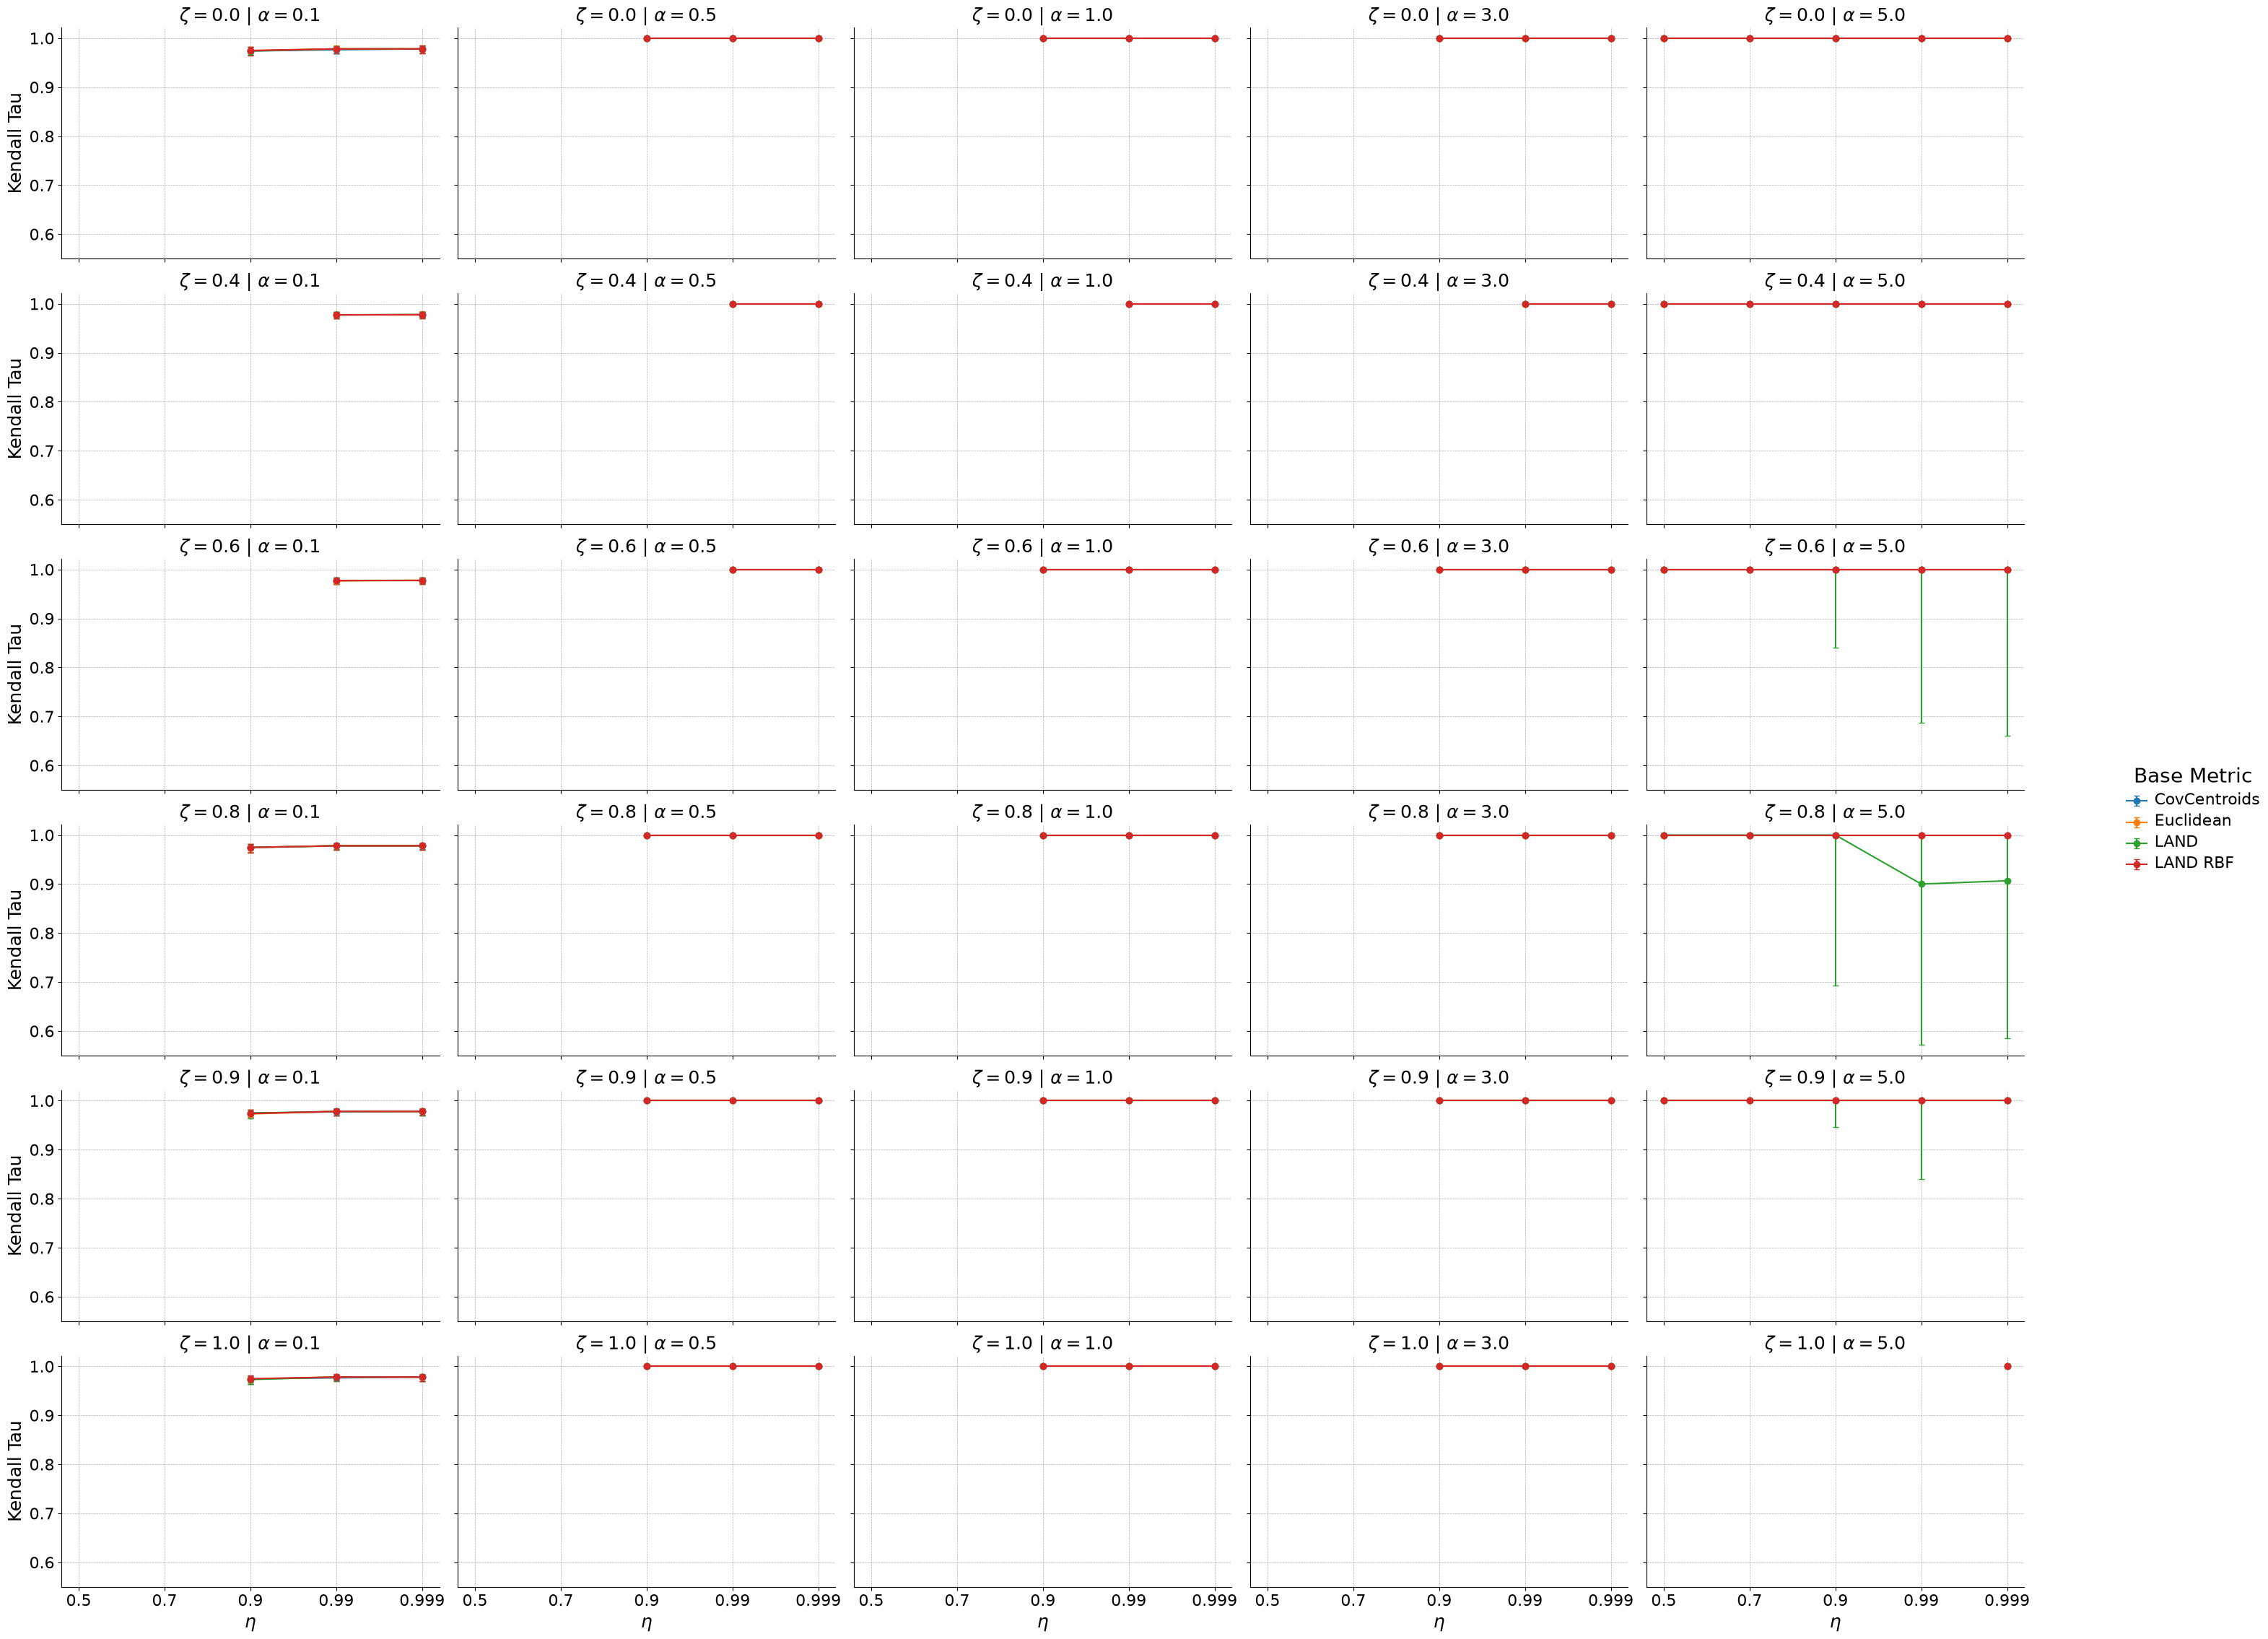

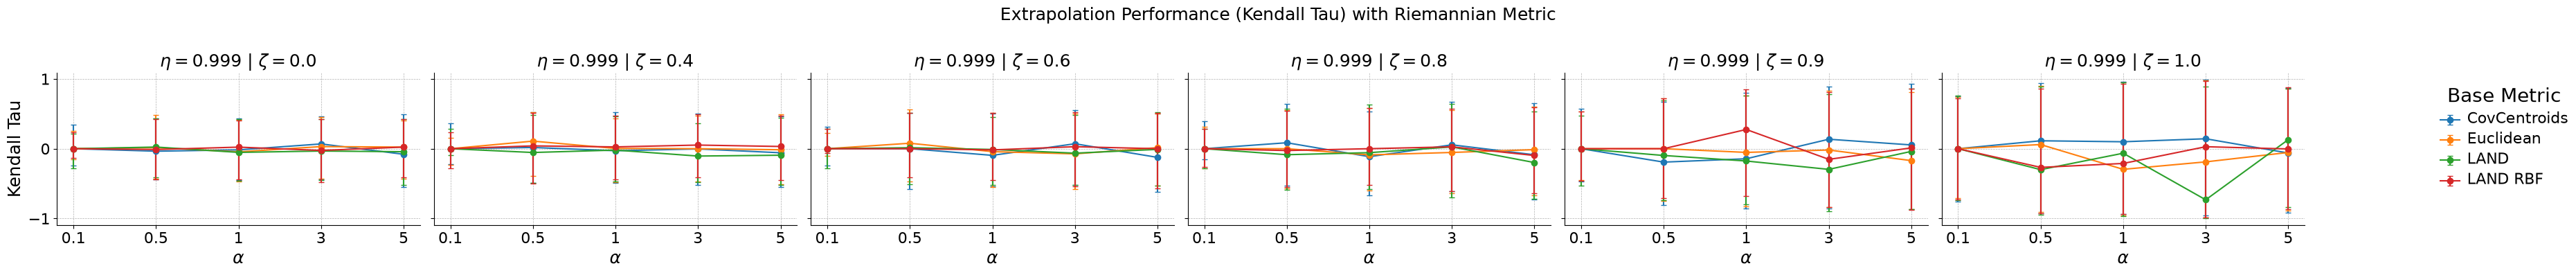

In [6]:
fig_finsler_tau = plot_extrapolation_performance(
    df_mono_extra,
    y="Kendall Tau Median",
    finsler=True,
    #  suptitle="Extrapolation Performance (Kendall Tau) with Randers Metric",
)
paper_image_dir = base_path.parents[2] / "finsler_latent_explo_paper" / "imgs"
# paper_image_dir.mkdir(parents=True, exist_ok=True)
# fig_finsler_tau.savefig(paper_image_dir / "extrapolation_ablation_randers_kendalltau.pdf", bbox_inches="tight")
fig_riemannian_tau = plot_extrapolation_performance_symmetric(
    df_mono_extra,
    y="Kendall Tau Median",
    suptitle="Extrapolation Performance (Kendall Tau) with Riemannian Metric",
)
# fig_riemannian_tau.savefig(paper_image_dir / "extrapolation_ablation_riemannian_kendalltau.pdf", bbox_inches="tight")

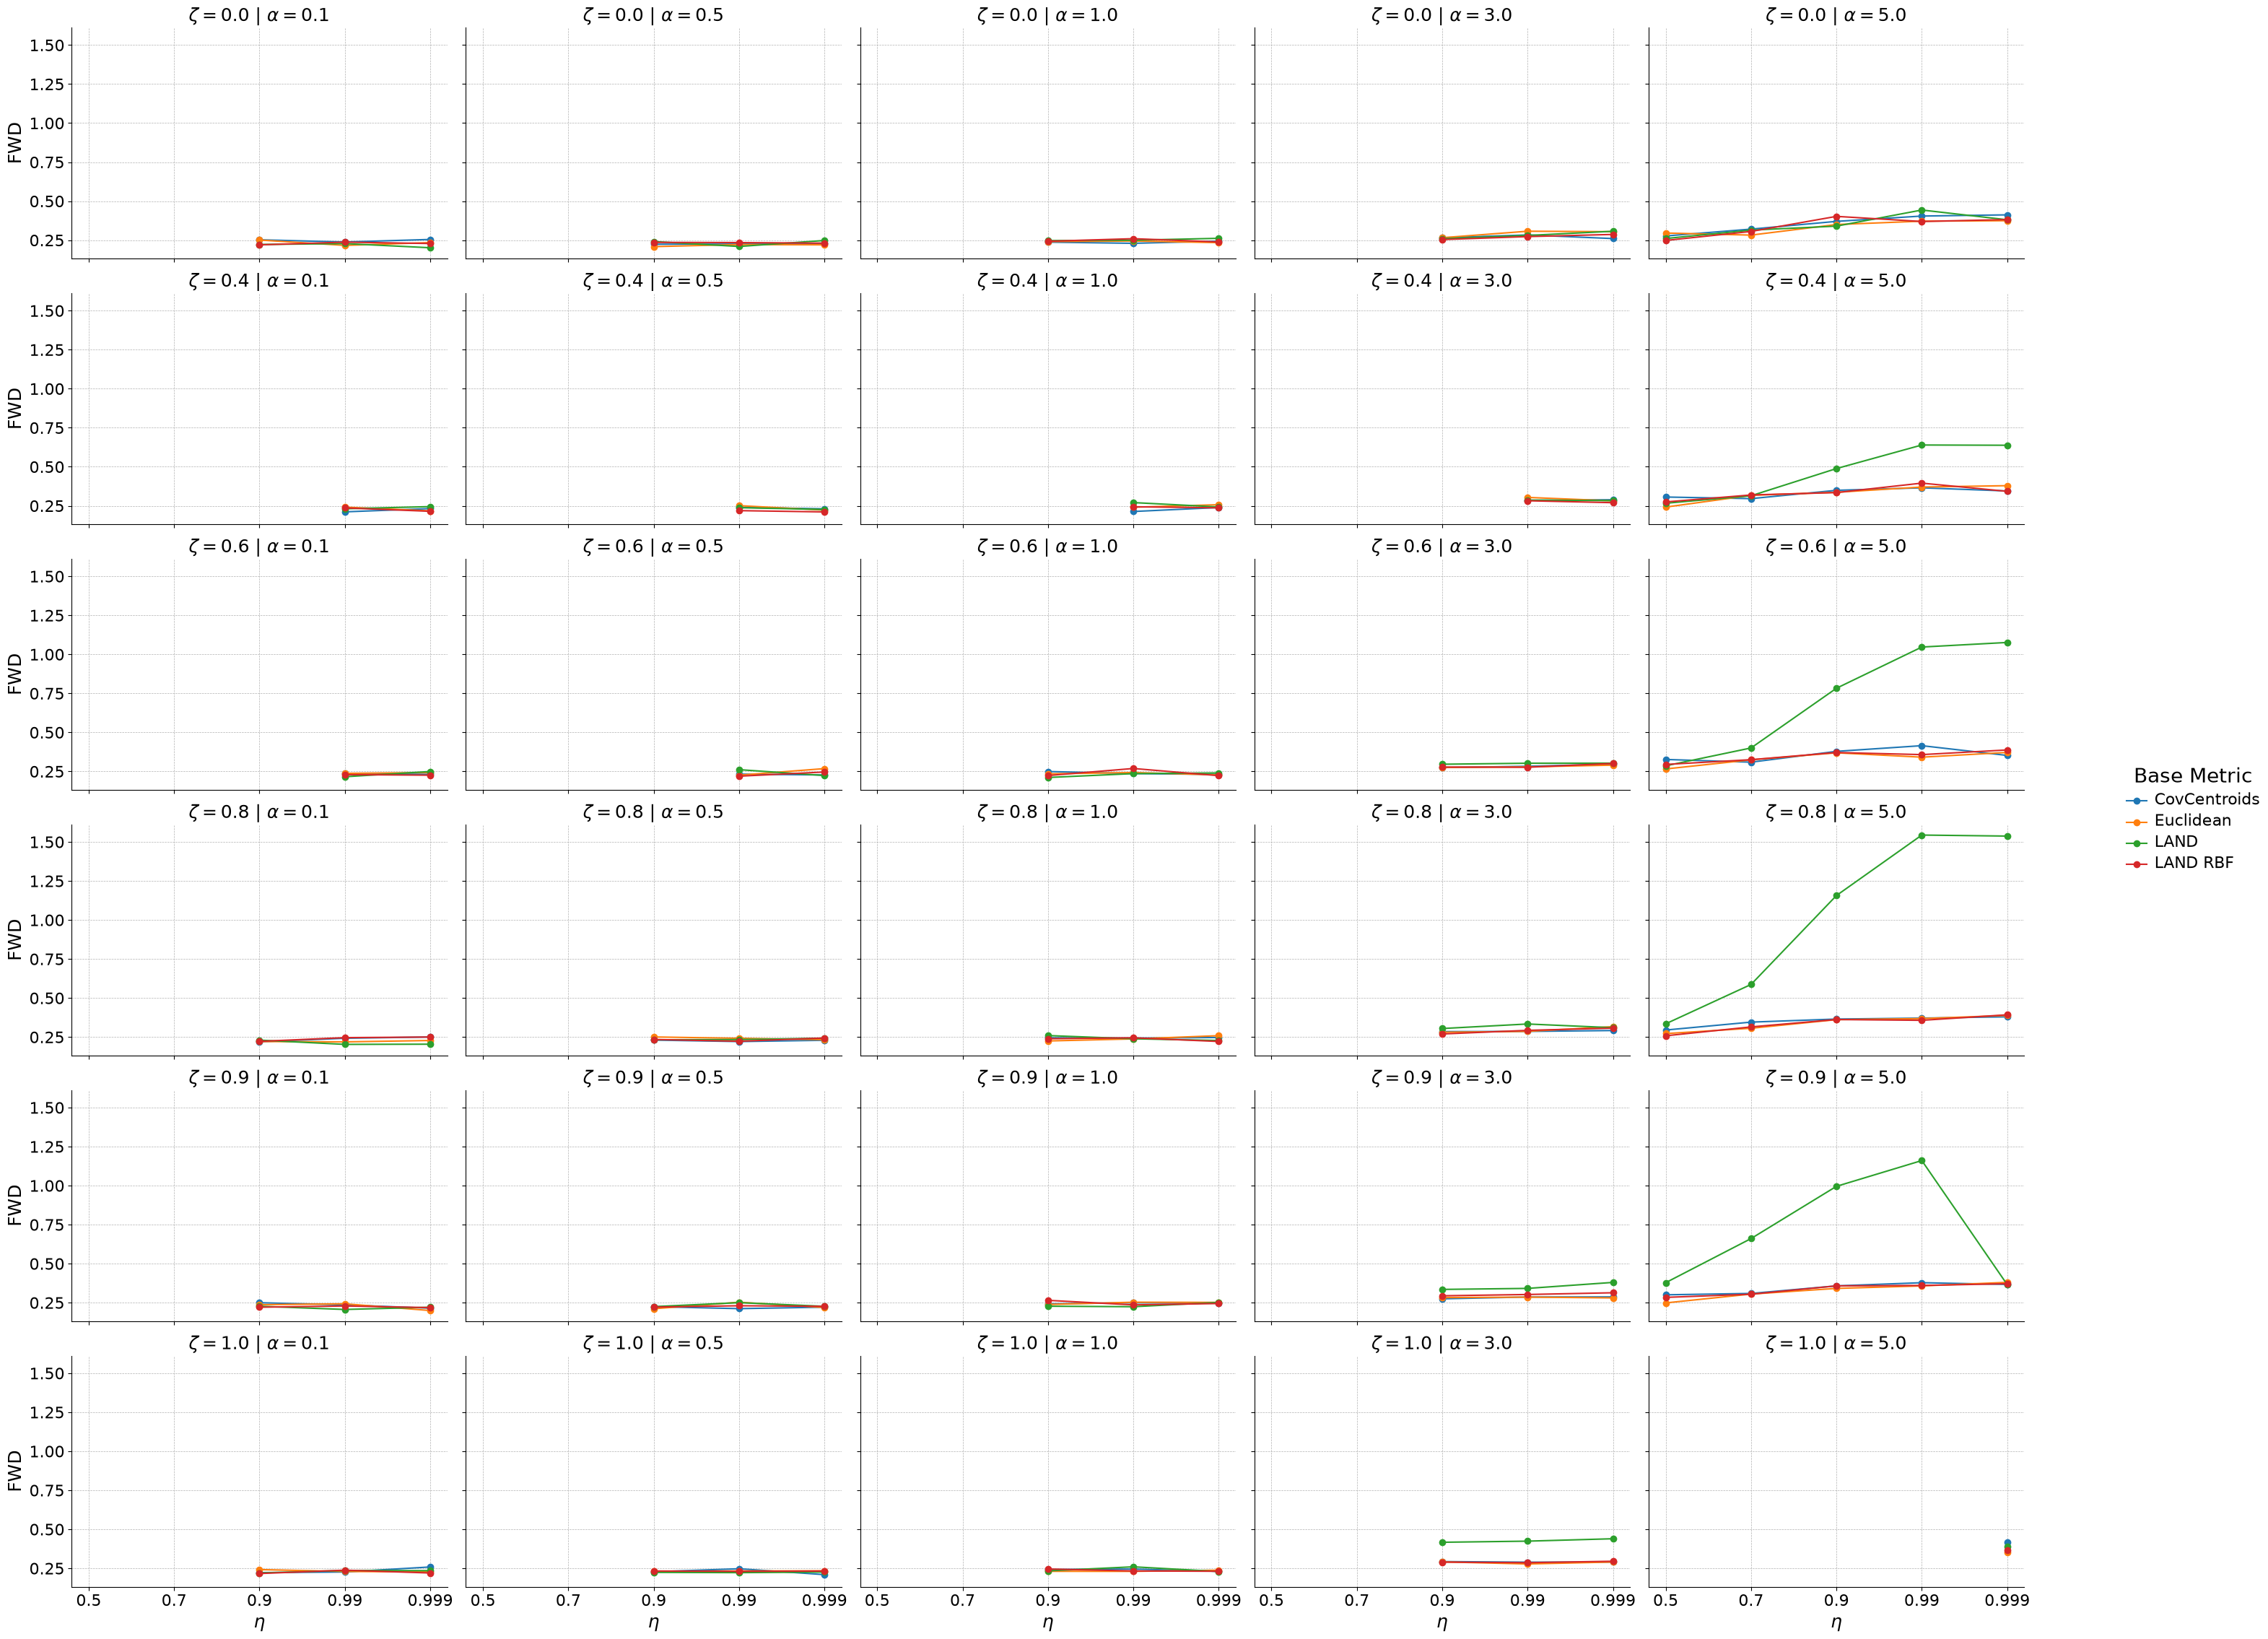

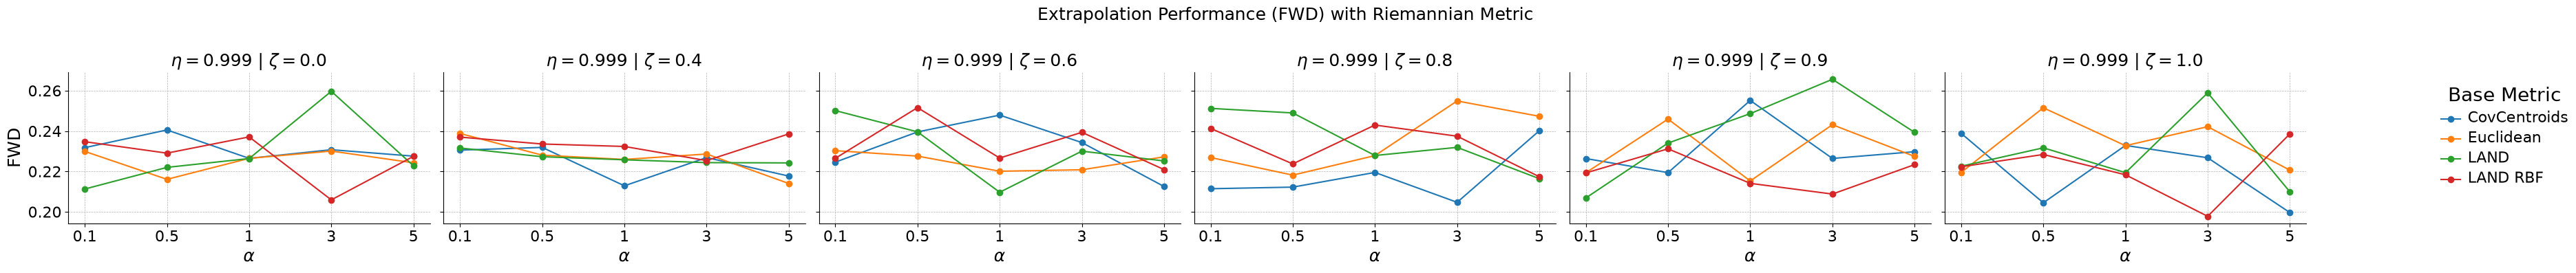

In [7]:
fig_finsler_fwd = plot_extrapolation_performance(
    df_mono_extra,
    y="FWD",
    finsler=True,
)
# fig_finsler_fwd.savefig(paper_image_dir / "extrapolation_ablation_randers_fwd.pdf", bbox_inches="tight")
fig_riemannian_fwd = plot_extrapolation_performance_symmetric(
    df_mono_extra,
    y="FWD",
    suptitle="Extrapolation Performance (FWD) with Riemannian Metric",
)
# fig_riemannian_fwd.savefig(paper_image_dir / "extrapolation_ablation_riemannian_fwd.pdf", bbox_inches="tight")

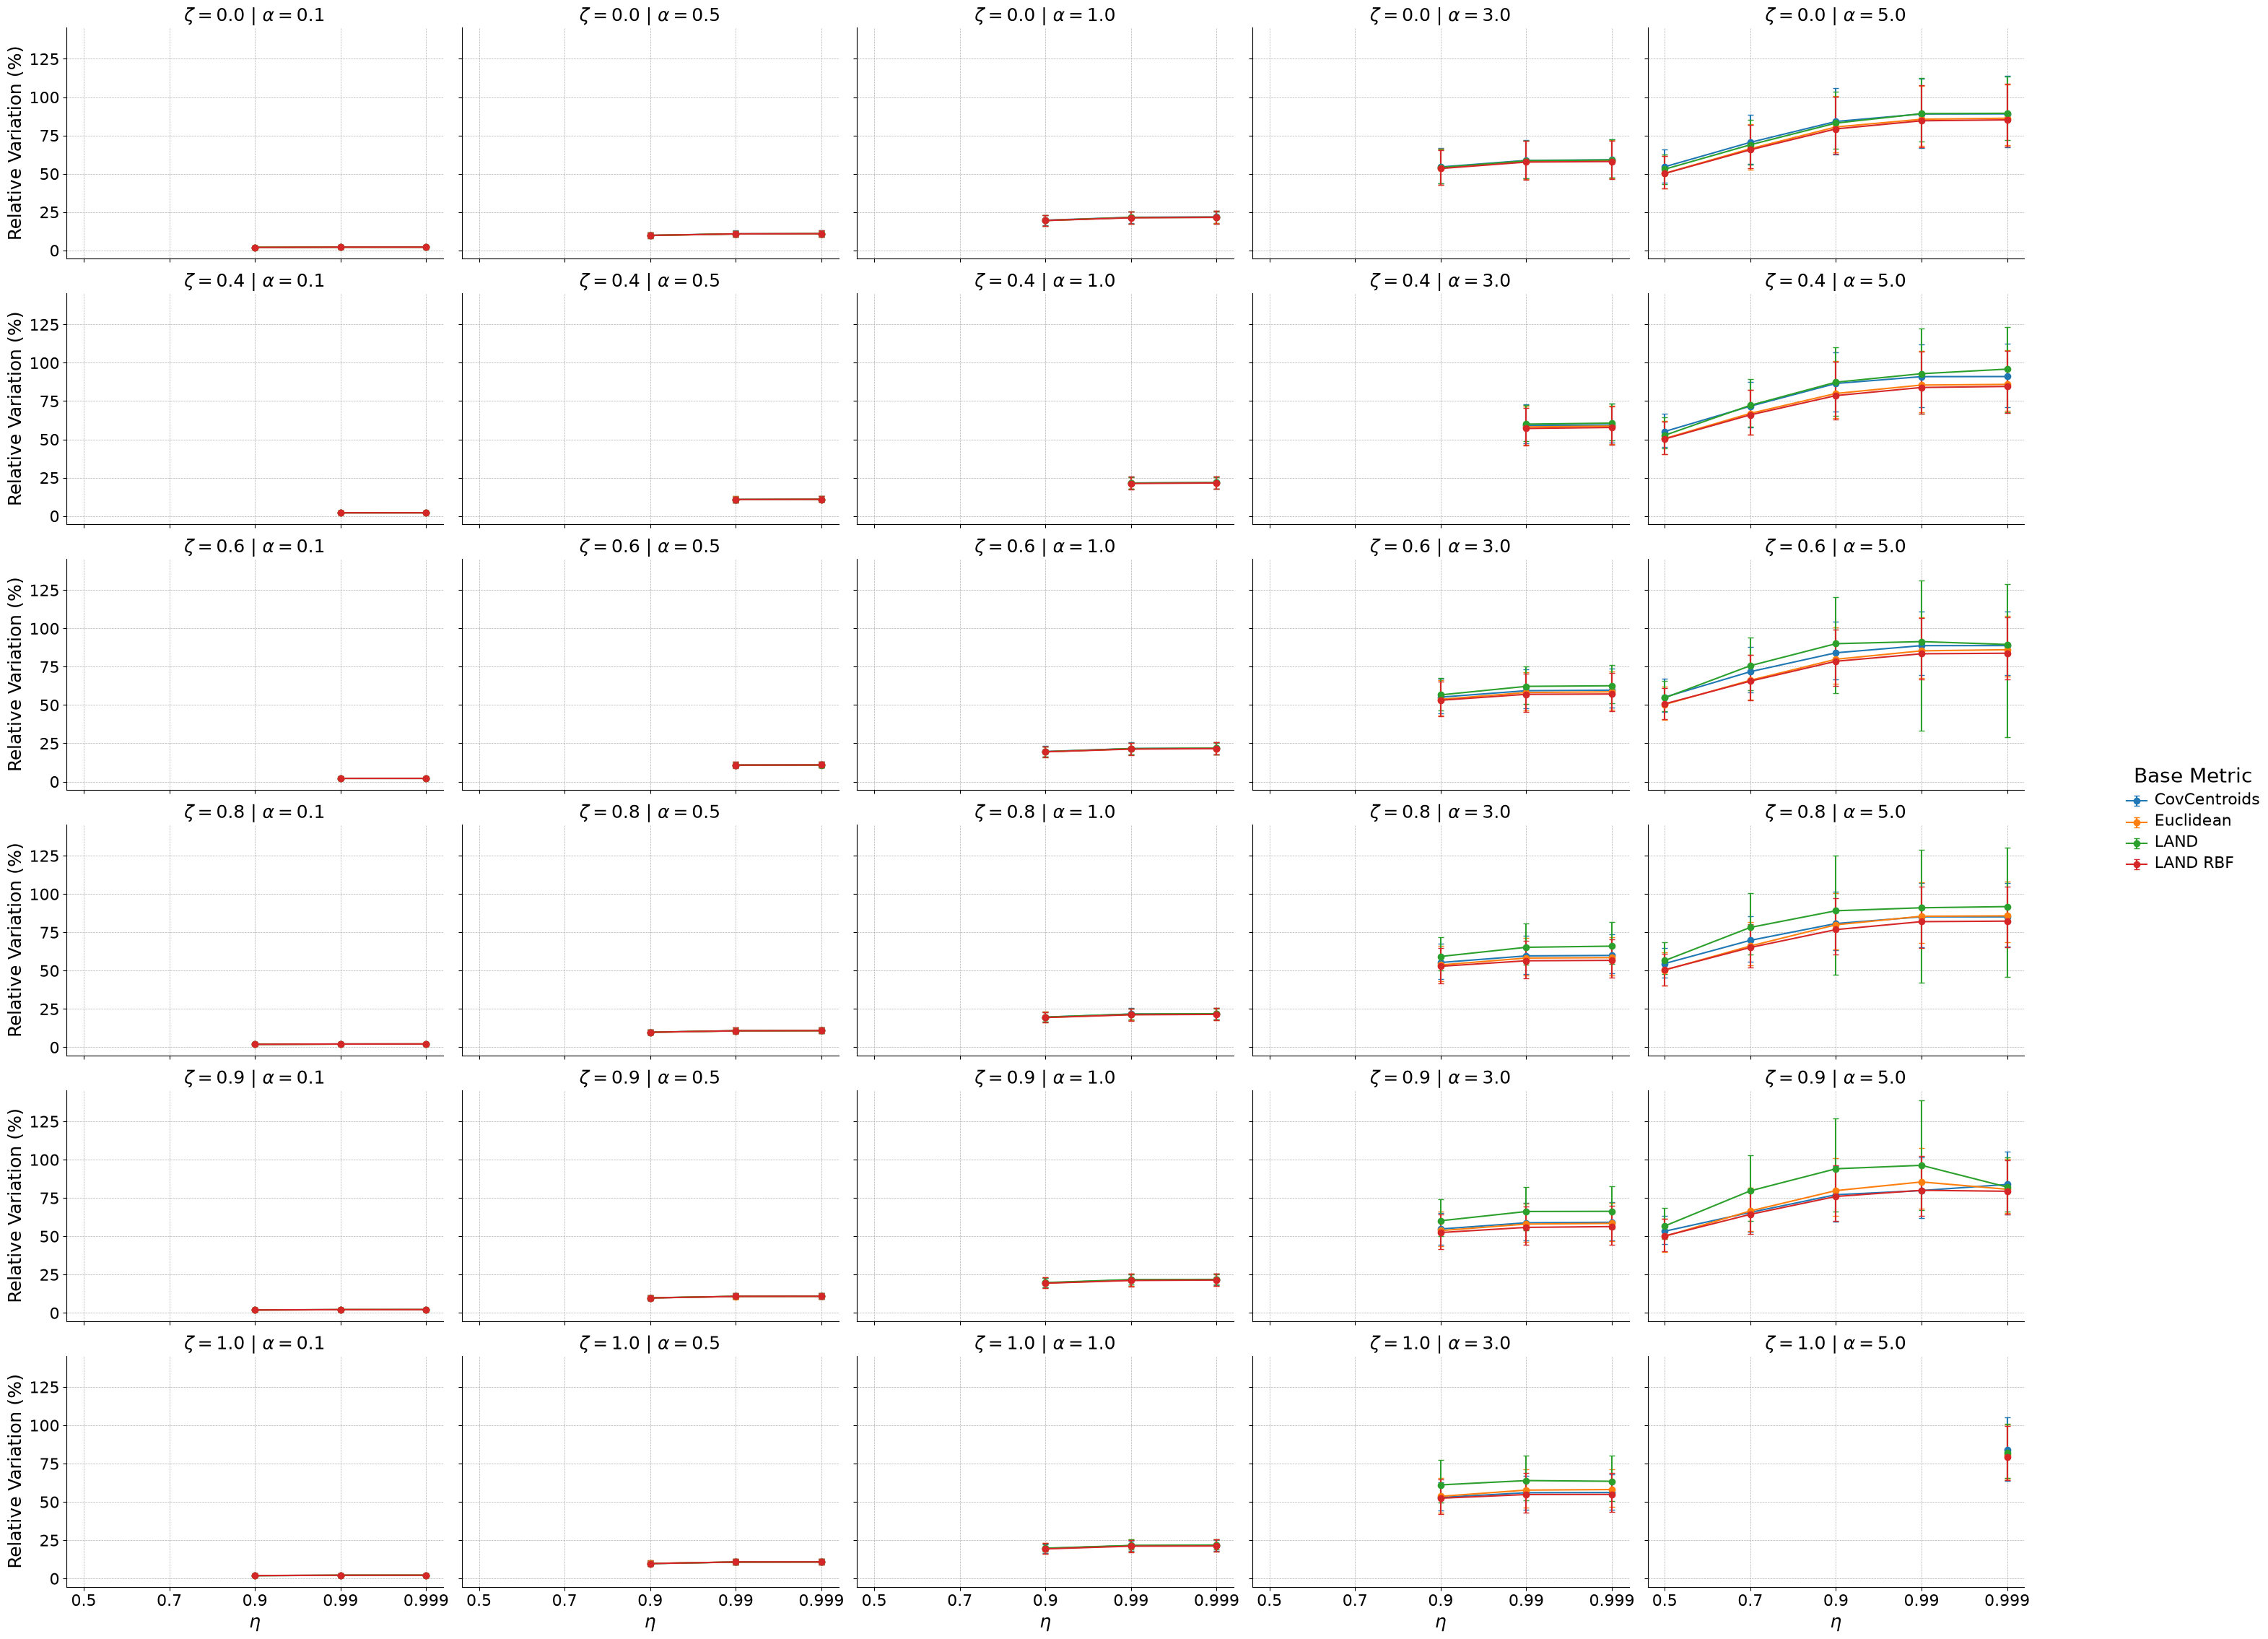

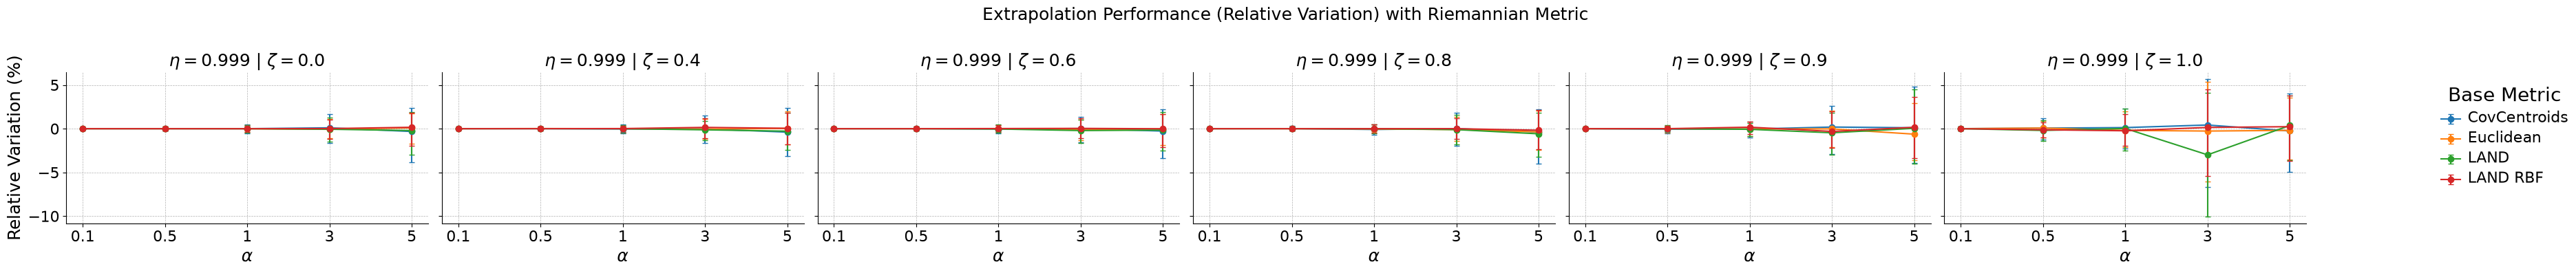

In [8]:
fig_finsler_rv = plot_extrapolation_performance(
    df_mono_extra,
    y="Relative Variation Median",
    finsler=True,
)
# fig_finsler_rv.savefig(paper_image_dir / "extrapolation_ablation_randers_rv.pdf", bbox_inches="tight")
fig_riemannian_rv = plot_extrapolation_performance_symmetric(
    df_mono_extra,
    y="Relative Variation Median",
    suptitle="Extrapolation Performance (Relative Variation) with Riemannian Metric",
)
# fig_riemannian_rv.savefig(paper_image_dir / "extrapolation_ablation_riemannian_rv.pdf", bbox_inches="tight")